In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df = pd.read_csv("beauty_preprocessed.csv")
customer_df = pd.read_csv("customer_features_preprocessed.csv")
df["Order Date"] = pd.to_datetime(df["Order Date"], errors="coerce")
print("TRANSACTION DATASET")
print("Shape:", df.shape)
print("Unique Customers:", df["Customer ID"].nunique())
print("Unique Orders:", df["Order ID"].nunique())
print("Date Range:", df["Order Date"].min(), "to", df["Order Date"].max())

print("\nCUSTOMER DATASET")
print("Shape:", customer_df.shape)

print("\nMissing Values")
print("Transaction Dataset:", df.isnull().sum().sum())
print("Customer Dataset:", customer_df.isnull().sum().sum())

print("\nDuplicate Rows")
print("Transaction Dataset:", df.duplicated().sum())
print("Customer Dataset:", customer_df.duplicated().sum())


TRANSACTION DATASET
Shape: (51290, 19)
Unique Customers: 17415
Unique Orders: 25728
Date Range: 2020-01-01 00:00:00 to 2023-12-31 00:00:00

CUSTOMER DATASET
Shape: (17415, 9)

Missing Values
Transaction Dataset: 0
Customer Dataset: 0

Duplicate Rows
Transaction Dataset: 0
Customer Dataset: 0


In [2]:

numerical_columns = ["Quantity", "Sales", "Discount", "Profit"]

# 1. Descriptive statistics
print("===== DESCRIPTIVE STATISTICS =====")

print(
    df[numerical_columns]
    .describe()
    .round(3)
    .to_string()
)

print("\n===== ADDITIONAL STATISTICAL MEASURES =====")

for column in numerical_columns:
    series = df[column]

    print(f"\n--- {column} ---")
    print("Mean:", round(series.mean(), 3))
    print("Median:", round(series.median(), 3))
    print("Mode:", series.mode().tolist()[:5])
    print("Standard Deviation:", round(series.std(), 3))
    print("Variance:", round(series.var(), 3))
    print("Skewness:", round(series.skew(), 3))
    print("Kurtosis:", round(series.kurtosis(), 3))
    print("Q1 (25th percentile):", round(series.quantile(0.25), 3))
    print("Q3 (75th percentile):", round(series.quantile(0.75), 3))
    print("IQR:", round(
        series.quantile(0.75) - series.quantile(0.25), 3
    ))


print("\n===== IQR OUTLIER ANALYSIS =====")

outlier_results = []

for column in numerical_columns:
    series = df[column]

    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_mask = (series < lower_bound) | (series > upper_bound)
    outlier_count = int(outlier_mask.sum())
    outlier_percentage = outlier_count / len(series) * 100

    outlier_results.append({
        "Feature": column,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outlier_count,
        "Outlier Percentage": outlier_percentage
    })

outlier_df = pd.DataFrame(outlier_results)

print(outlier_df.round(3).to_string(index=False))


===== DESCRIPTIVE STATISTICS =====
        Quantity      Sales   Discount     Profit
count  51290.000  51290.000  51290.000  51290.000
mean       5.416    127.075      0.143     20.772
std        4.908    236.075      0.212     83.583
min        1.000      2.000      0.000  -1746.000
25%        2.000     25.000      0.000      0.000
50%        4.000     56.000      0.000      7.200
75%        7.000    132.000      0.200     25.000
max       20.000   3940.000      0.850   1820.000

===== ADDITIONAL STATISTICAL MEASURES =====

--- Quantity ---
Mean: 5.416
Median: 4.0
Mode: [2]
Standard Deviation: 4.908
Variance: 24.091
Skewness: 1.469
Kurtosis: 1.196
Q1 (25th percentile): 2.0
Q3 (75th percentile): 7.0
IQR: 5.0

--- Sales ---
Mean: 127.075
Median: 56.0
Mode: [36]
Standard Deviation: 236.075
Variance: 55731.294
Skewness: 6.402
Kurtosis: 60.608
Q1 (25th percentile): 25.0
Q3 (75th percentile): 132.0
IQR: 107.0

--- Discount ---
Mean: 0.143
Median: 0.0
Mode: [0.0]
Standard Deviation: 0.212
Va

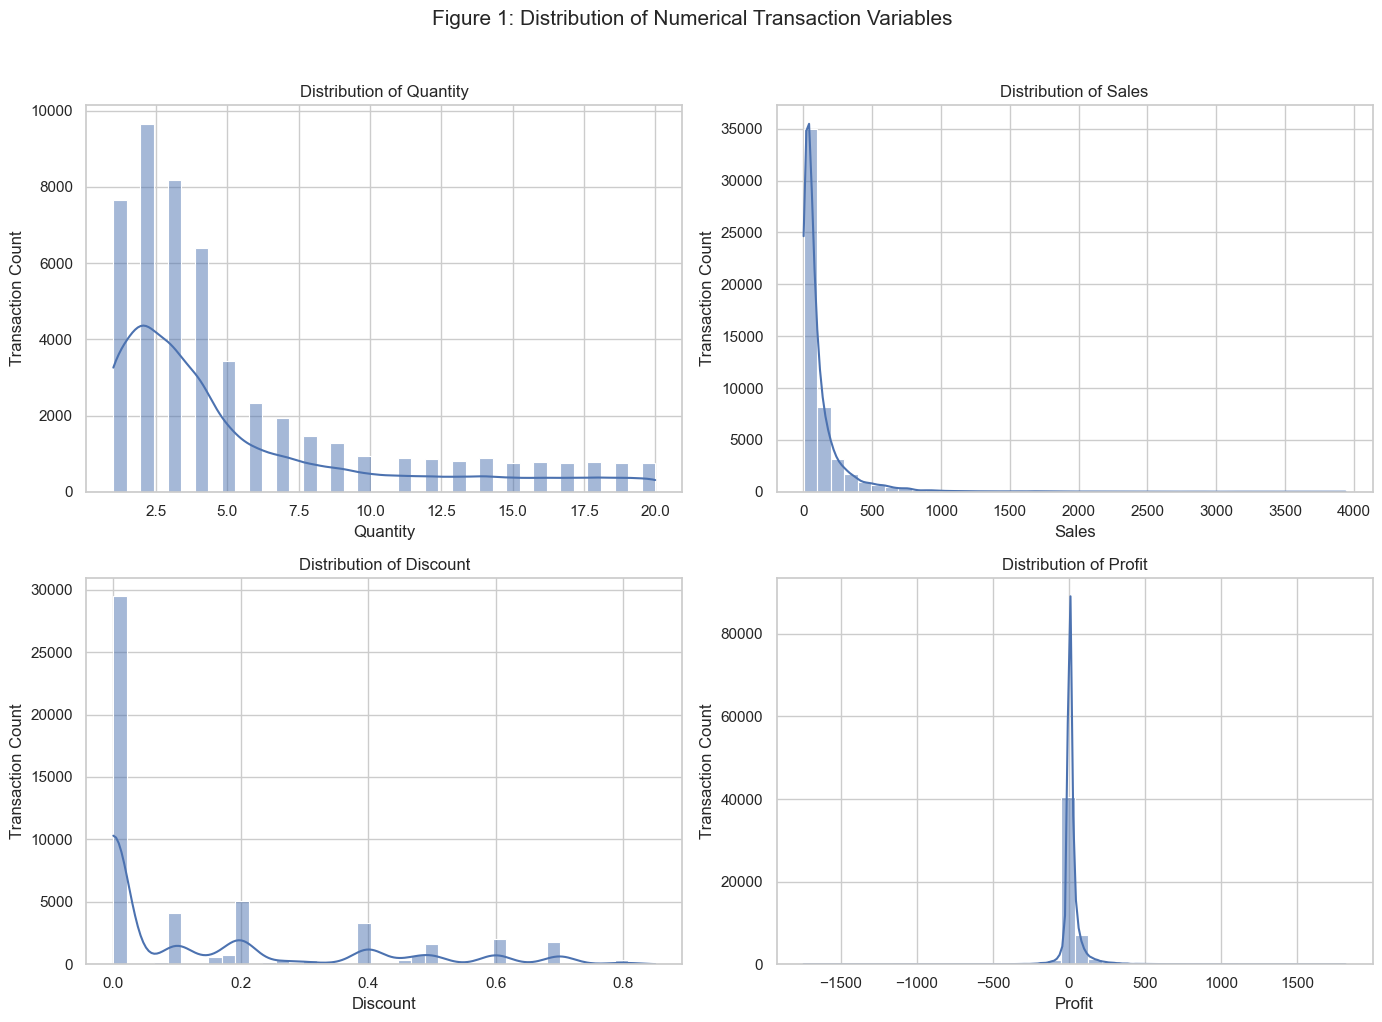

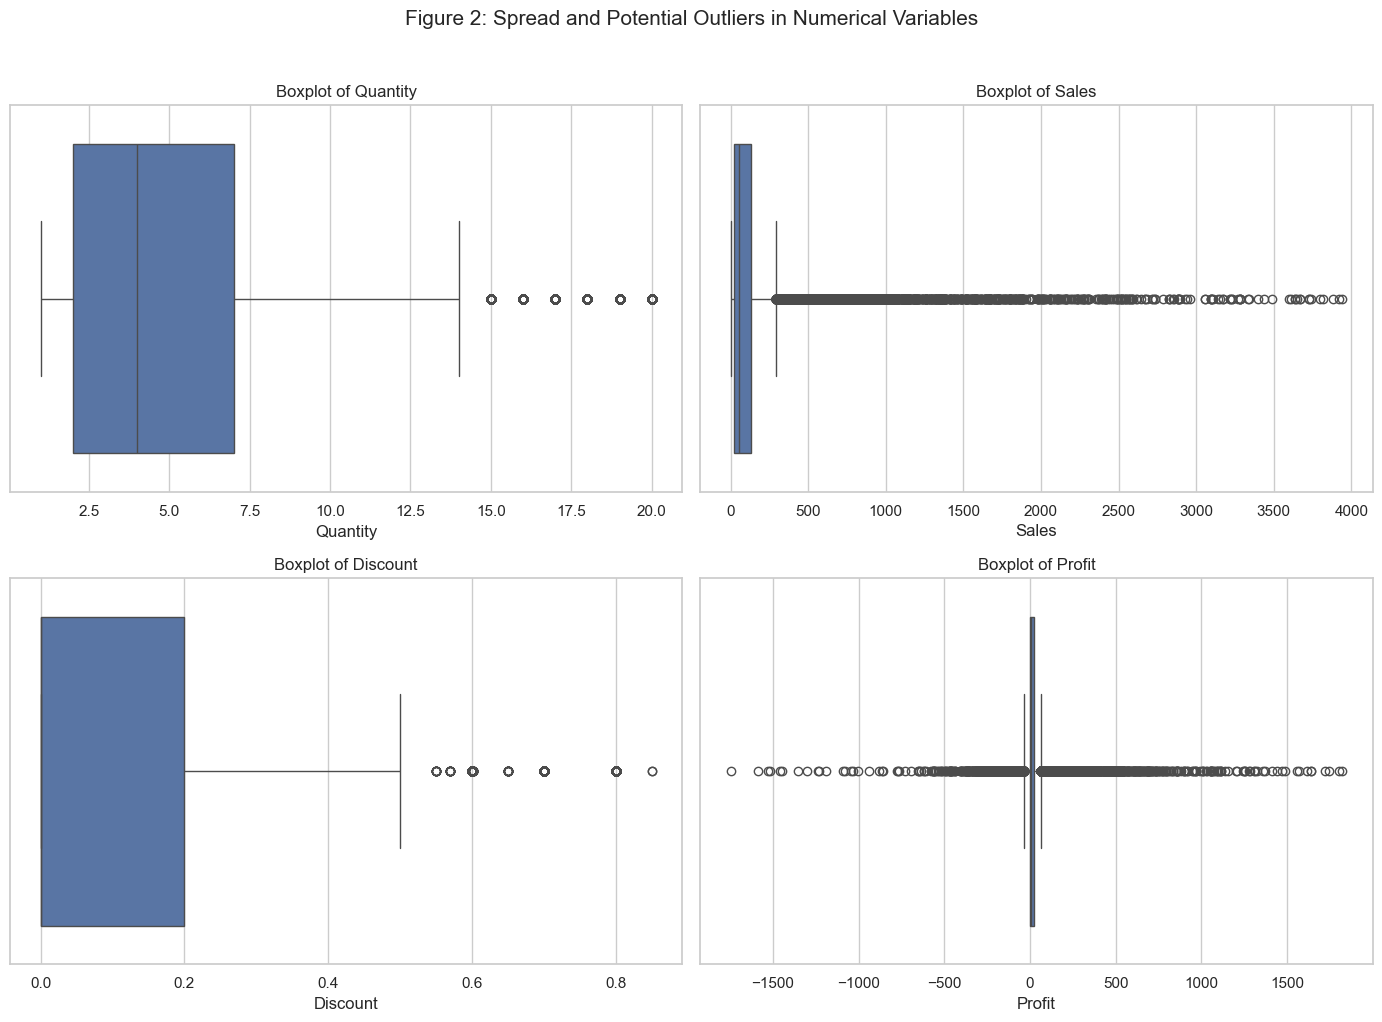

Saved:
1. week4_numerical_distributions.png
2. week4_numerical_boxplots.png


In [3]:
sns.set_theme(style="whitegrid", context="notebook")
numerical_columns = ["Quantity", "Sales", "Discount", "Profit"]
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, column in zip(axes.flatten(), numerical_columns):
    sns.histplot(
        data=df,
        x=column,
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {column}", fontsize=12)
    ax.set_xlabel(column)
    ax.set_ylabel("Transaction Count")

plt.suptitle(
    "Figure 1: Distribution of Numerical Transaction Variables",
    fontsize=15,
    y=1.02
)
plt.tight_layout()
plt.savefig("week4_numerical_distributions.png",
            dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, column in zip(axes.flatten(), numerical_columns):
    sns.boxplot(
        data=df,
        x=column,
        ax=ax
    )
    ax.set_title(f"Boxplot of {column}", fontsize=12)
    ax.set_xlabel(column)

plt.suptitle(
    "Figure 2: Spread and Potential Outliers in Numerical Variables",
    fontsize=15,
    y=1.02
)
plt.tight_layout()
plt.savefig("week4_numerical_boxplots.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Saved:")
print("1. week4_numerical_distributions.png")
print("2. week4_numerical_boxplots.png")


===== MONTHLY TREND SAMPLE =====
Year_Month  Total_Sales  Total_Profit  Unique_Orders
   2020-01        50460      10290.50            216
   2020-02        49815       8443.90            203
   2020-03        62773      13435.53            266
   2020-04        68707      11588.65            258
   2020-05        73493      14027.57            317
   2020-06       122286      21809.29            454
   2020-07        70993      10656.06            262
   2020-08       105207      20400.21            445
   2020-09       133633      25514.57            516
   2020-10       107889      17647.26            425
   2020-11       142135      26512.76            556
   2020-12       160970      26789.84            597

===== YEARLY TREND AND GROWTH =====
 Year  Total_Sales  Total_Profit  Unique_Orders  Sales_Growth_Pct  Profit_Growth_Pct  Orders_Growth_Pct
 2020      1148361     207116.12           4515               NaN                NaN                NaN
 2021      1405876     259696.96 

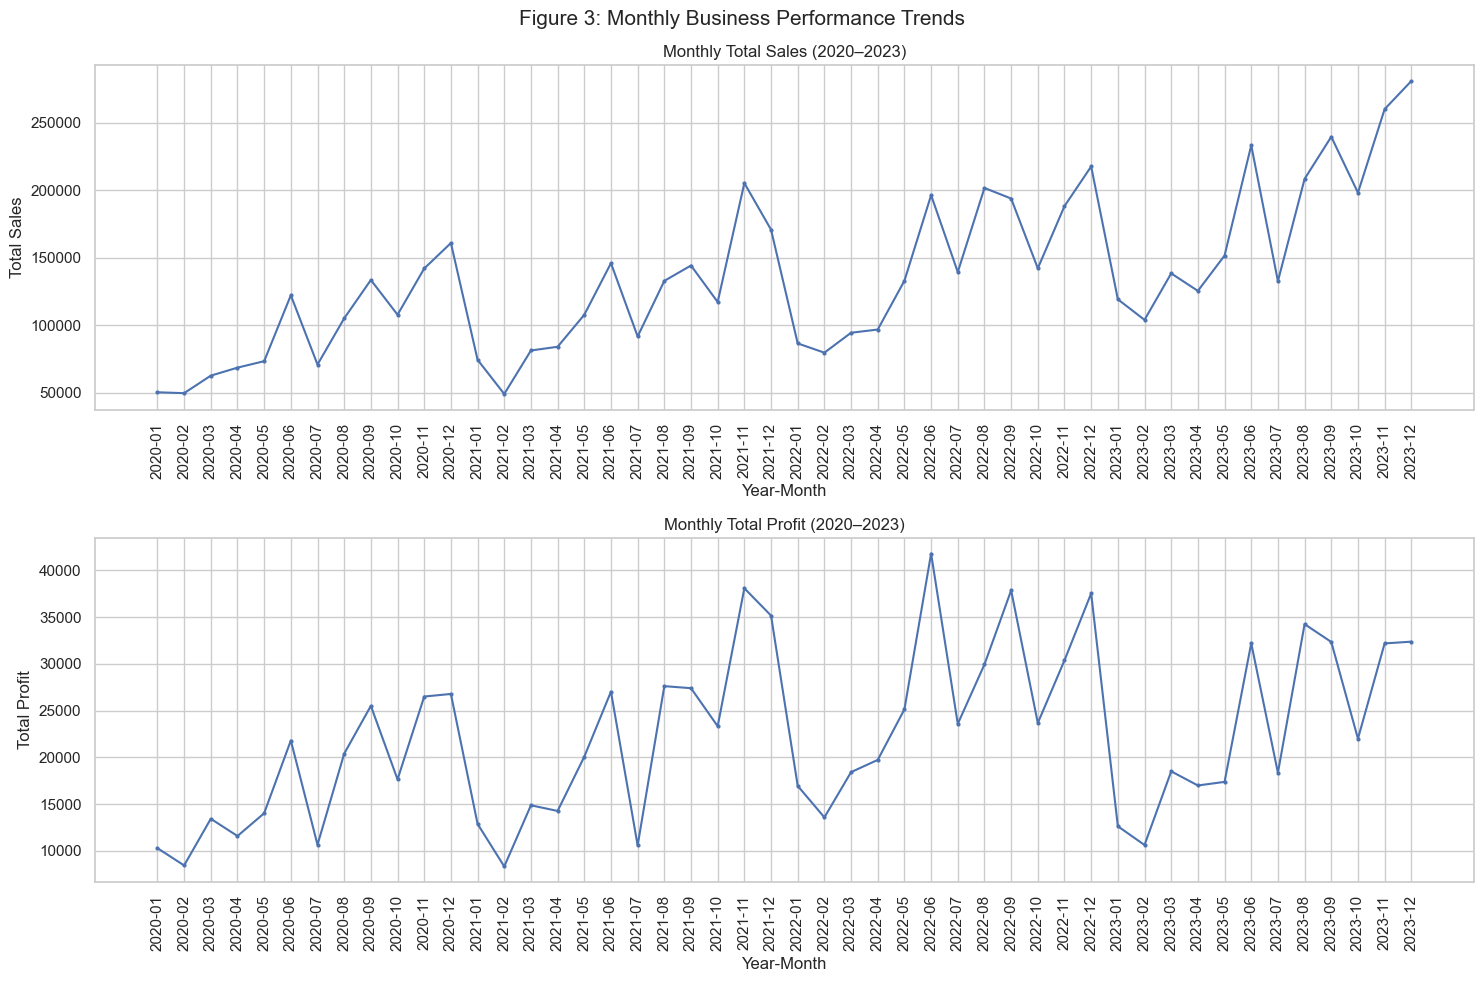

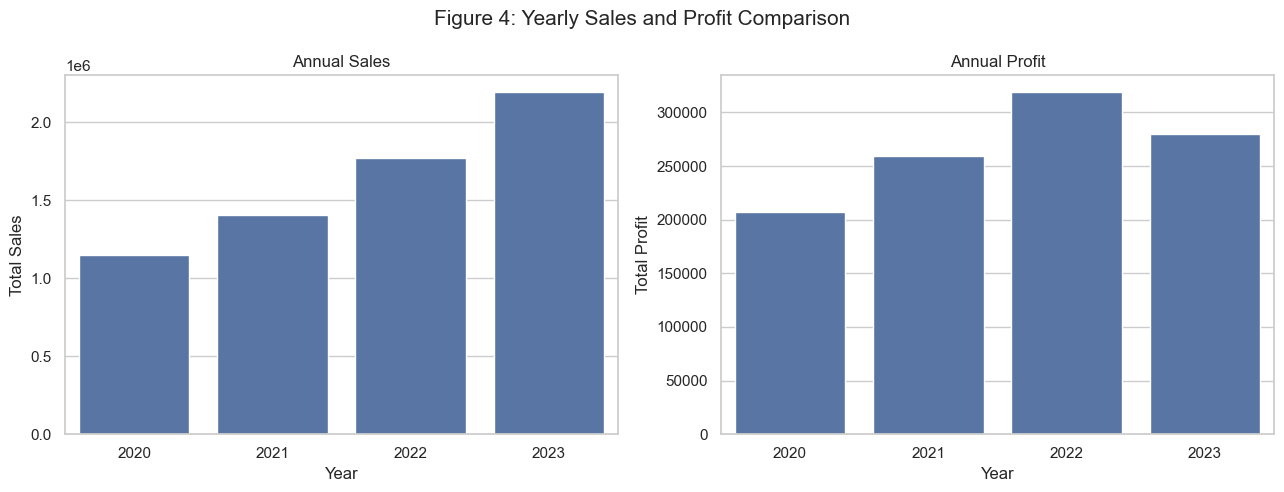


Saved:
week4_monthly_trends.png
week4_yearly_comparison.png


In [4]:


df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year_Month"] = df["Order Date"].dt.to_period("M").astype(str)


monthly_trend = (
    df.groupby("Year_Month")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Unique_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

print("===== MONTHLY TREND SAMPLE =====")
print(monthly_trend.head(12).round(2).to_string(index=False))

yearly_trend = (
    df.groupby("Year")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Unique_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

yearly_trend["Sales_Growth_Pct"] = (
    yearly_trend["Total_Sales"].pct_change() * 100
)

yearly_trend["Profit_Growth_Pct"] = (
    yearly_trend["Total_Profit"].pct_change() * 100
)

yearly_trend["Orders_Growth_Pct"] = (
    yearly_trend["Unique_Orders"].pct_change() * 100
)

print("\n===== YEARLY TREND AND GROWTH =====")
print(yearly_trend.round(2).to_string(index=False))

fig, axes = plt.subplots(2, 1, figsize=(15, 10))

axes[0].plot(
    monthly_trend["Year_Month"],
    monthly_trend["Total_Sales"],
    marker="o",
    markersize=2
)
axes[0].set_title("Monthly Total Sales (2020–2023)")
axes[0].set_ylabel("Total Sales")
axes[0].set_xlabel("Year-Month")
axes[0].tick_params(axis="x", rotation=90)

axes[1].plot(
    monthly_trend["Year_Month"],
    monthly_trend["Total_Profit"],
    marker="o",
    markersize=2
)
axes[1].set_title("Monthly Total Profit (2020–2023)")
axes[1].set_ylabel("Total Profit")
axes[1].set_xlabel("Year-Month")
axes[1].tick_params(axis="x", rotation=90)

plt.suptitle("Figure 3: Monthly Business Performance Trends", fontsize=15)
plt.tight_layout()
plt.savefig("week4_monthly_trends.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=yearly_trend,
    x="Year",
    y="Total_Sales",
    ax=axes[0]
)
axes[0].set_title("Annual Sales")
axes[0].set_ylabel("Total Sales")

sns.barplot(
    data=yearly_trend,
    x="Year",
    y="Total_Profit",
    ax=axes[1]
)
axes[1].set_title("Annual Profit")
axes[1].set_ylabel("Total Profit")

plt.suptitle("Figure 4: Yearly Sales and Profit Comparison", fontsize=15)
plt.tight_layout()
plt.savefig("week4_yearly_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved:")
print("week4_monthly_trends.png")
print("week4_yearly_comparison.png")


===== CATEGORY-WISE BUSINESS PERFORMANCE =====
            Category  Total_Sales  Total_Profit  Total_Quantity  Unique_Orders  Unique_Customers  Average_Discount  Profit_Margin_Pct
           body care      2682942     590907.78          113437          14855             11648              0.15              22.02
home and accessories      1245643     -57187.64           52847           7986              6970              0.14              -4.59
             make up      1121222     368998.18           48284           7613              6689              0.13              32.91
           hair care      1022151       3677.23           43994           7067              6269              0.14               0.36
           face care       445716     159018.10           19216           3199              2910              0.11              35.68

===== MARKET-WISE BUSINESS PERFORMANCE =====
      Market  Total_Sales  Total_Profit  Total_Quantity  Unique_Orders  Unique_Customers  Average_Disco

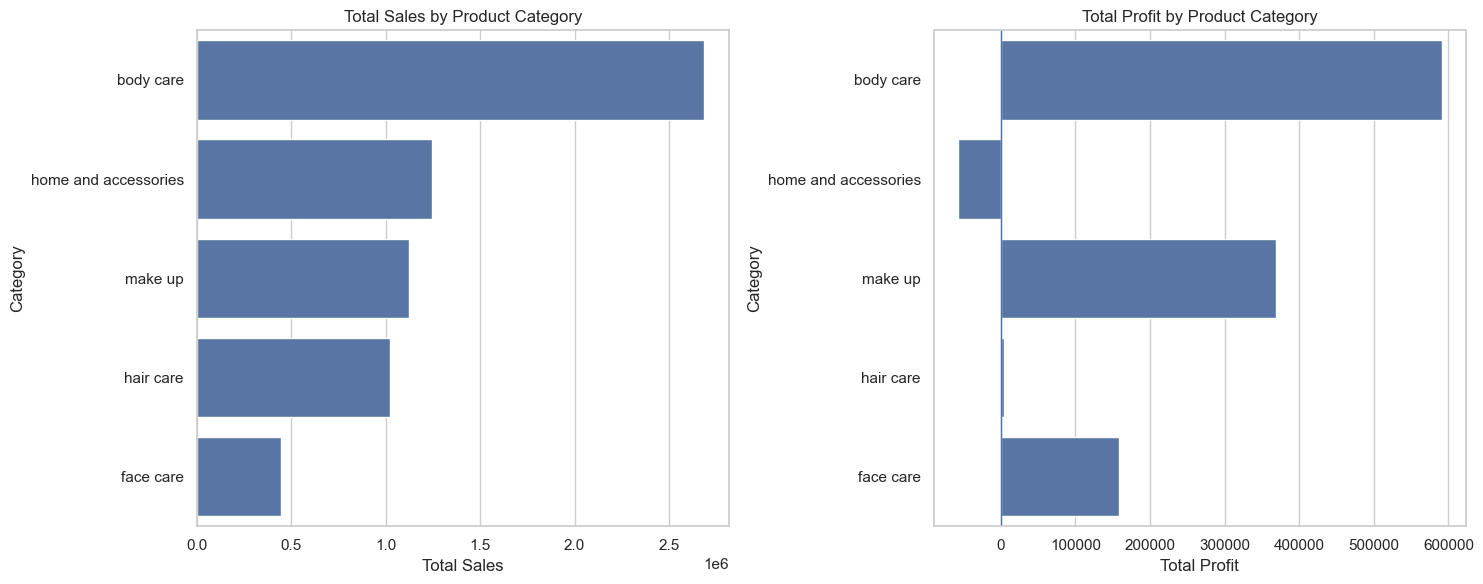

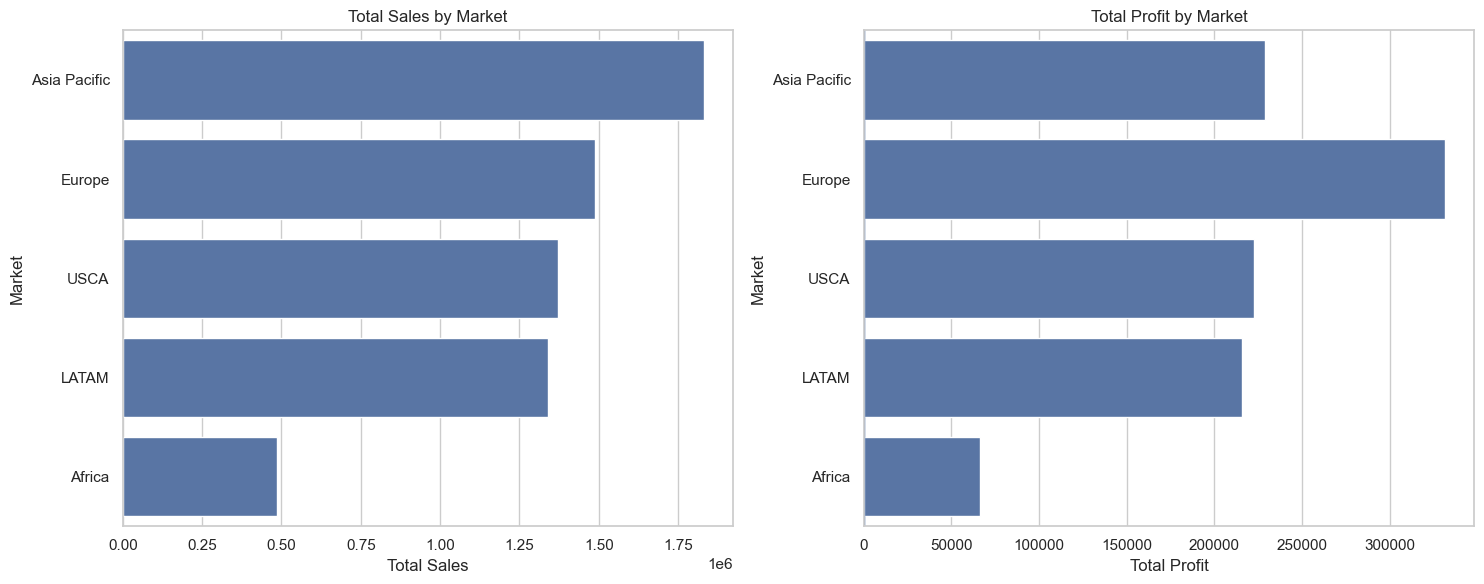


Figures saved:
1. week4_category_performance.png
2. week4_market_performance.png


In [5]:

# STEP 5: Category-wise and Market-wise Business Analysis

# 1. Category-wise performance
category_analysis = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

category_analysis["Profit_Margin_Pct"] = (
    category_analysis["Total_Profit"]
    / category_analysis["Total_Sales"] * 100
)

category_analysis = category_analysis.sort_values(
    "Total_Sales", ascending=False
)

print("===== CATEGORY-WISE BUSINESS PERFORMANCE =====")
print(category_analysis.round(2).to_string(index=False))


# 2. Market-wise performance
market_analysis = (
    df.groupby("Market")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique"),
        Average_Discount=("Discount", "mean")
    )
    .reset_index()
)

market_analysis["Profit_Margin_Pct"] = (
    market_analysis["Total_Profit"]
    / market_analysis["Total_Sales"] * 100
)

market_analysis = market_analysis.sort_values(
    "Total_Sales", ascending=False
)

print("\n===== MARKET-WISE BUSINESS PERFORMANCE =====")
print(market_analysis.round(2).to_string(index=False))


# 3. Visualize category sales and profit
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=category_analysis,
    x="Total_Sales",
    y="Category",
    ax=axes[0]
)
axes[0].set_title("Total Sales by Product Category")
axes[0].set_xlabel("Total Sales")

sns.barplot(
    data=category_analysis,
    x="Total_Profit",
    y="Category",
    ax=axes[1]
)
axes[1].set_title("Total Profit by Product Category")
axes[1].set_xlabel("Total Profit")
axes[1].axvline(0, linewidth=1)

plt.tight_layout()
plt.savefig(
    "week4_category_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# 4. Visualize market sales and profit
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.barplot(
    data=market_analysis,
    x="Total_Sales",
    y="Market",
    ax=axes[0]
)
axes[0].set_title("Total Sales by Market")
axes[0].set_xlabel("Total Sales")

sns.barplot(
    data=market_analysis,
    x="Total_Profit",
    y="Market",
    ax=axes[1]
)
axes[1].set_title("Total Profit by Market")
axes[1].set_xlabel("Total Profit")
axes[1].axvline(0, linewidth=1)

plt.tight_layout()
plt.savefig(
    "week4_market_performance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


print("\nFigures saved:")
print("1. week4_category_performance.png")
print("2. week4_market_performance.png")


===== CUSTOMER ACTIVITY DISTRIBUTION =====
Activity_Status
Inactive    9768
Active      7647

===== ACTIVE VS INACTIVE CUSTOMER COMPARISON =====
                Recency                Frequency              Monetary                Total_Quantity               Total_Profit               Avg_Discount              Average_Order_Value               
                  count    mean median     count  mean median    count    mean median          count   mean median        count   mean median        count  mean median               count    mean median
Activity_Status                                                                                                                                                                                           
Active             7647  143.92  126.0      7647  1.75    1.0     7647  442.42  212.0           7647  18.89   11.0         7647  66.20  24.16         7647  0.14   0.05                7647  250.47  131.5
Inactive           9768  791.40  759.0     

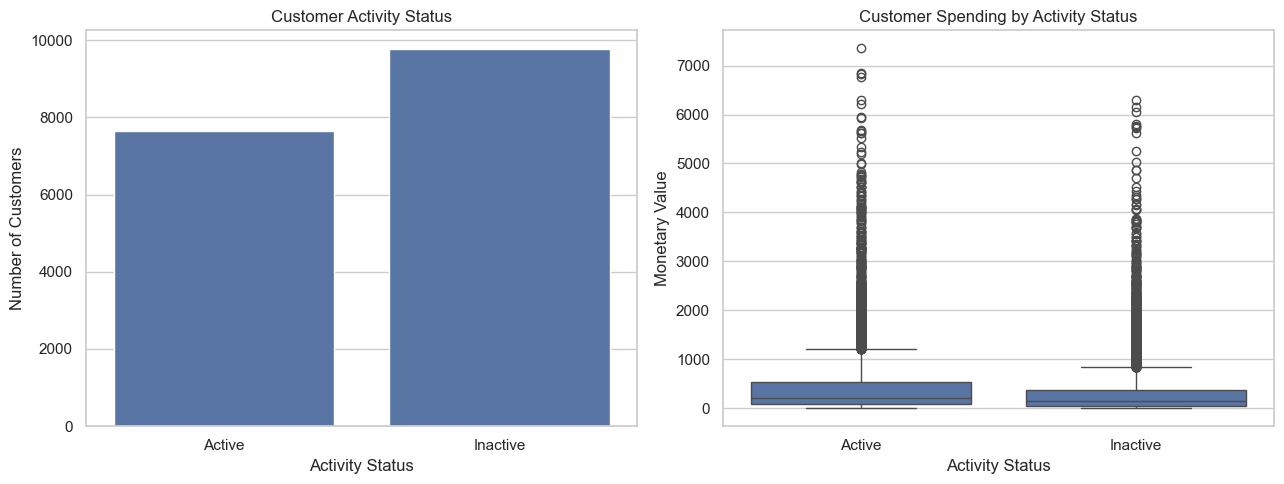


Figure saved: week4_customer_activity_analysis.png


In [6]:

# STEP 6: Customer Behaviour Analysis

print("===== CUSTOMER ACTIVITY DISTRIBUTION =====")
print(
    customer_df["Activity_Status"]
    .value_counts()
    .to_string()
)

# Compare numerical customer features
customer_metrics = [
    "Recency",
    "Frequency",
    "Monetary",
    "Total_Quantity",
    "Total_Profit",
    "Avg_Discount",
    "Average_Order_Value"
]

activity_summary = (
    customer_df.groupby("Activity_Status")[customer_metrics]
    .agg(["count", "mean", "median"])
    .round(2)
)

print("\n===== ACTIVE VS INACTIVE CUSTOMER COMPARISON =====")
print(activity_summary.to_string())


# Visualize customer activity
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=customer_df,
    x="Activity_Status",
    ax=axes[0]
)
axes[0].set_title("Customer Activity Status")
axes[0].set_xlabel("Activity Status")
axes[0].set_ylabel("Number of Customers")

sns.boxplot(
    data=customer_df,
    x="Activity_Status",
    y="Monetary",
    ax=axes[1]
)
axes[1].set_title("Customer Spending by Activity Status")
axes[1].set_xlabel("Activity Status")
axes[1].set_ylabel("Monetary Value")

plt.tight_layout()
plt.savefig(
    "week4_customer_activity_analysis.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("\nFigure saved: week4_customer_activity_analysis.png")


In [7]:

# STEP 7: Statistical Significance Testing

from scipy.stats import mannwhitneyu

print("===== ACTIVE VS INACTIVE: STATISTICAL TESTS =====")

active = customer_df[
    customer_df["Activity_Status"] == "Active"
]

inactive = customer_df[
    customer_df["Activity_Status"] == "Inactive"
]

test_columns = [
    "Frequency",
    "Monetary",
    "Total_Quantity",
    "Total_Profit",
    "Avg_Discount",
    "Average_Order_Value"
]

results = []

for column in test_columns:
    active_values = active[column].dropna()
    inactive_values = inactive[column].dropna()

    statistic, p_value = mannwhitneyu(
        active_values,
        inactive_values,
        alternative="two-sided"
    )

    results.append({
        "Metric": column,
        "Active_Median": active_values.median(),
        "Inactive_Median": inactive_values.median(),
        "U_Statistic": statistic,
        "P_Value": p_value,
        "Significant_At_0.05": p_value < 0.05
    })

test_results = pd.DataFrame(results)

print(test_results.round(5).to_string(index=False))

print("\nInterpretation rule:")
print("p < 0.05: statistically significant difference")
print("p >= 0.05: insufficient evidence of a difference")
print("\nSaved statistical results in variable: test_results")


===== ACTIVE VS INACTIVE: STATISTICAL TESTS =====
             Metric  Active_Median  Inactive_Median  U_Statistic  P_Value  Significant_At_0.05
          Frequency          1.000             1.00   47359431.0  0.00000                 True
           Monetary        212.000           144.00   42647513.5  0.00000                 True
     Total_Quantity         11.000             8.00   43139228.0  0.00000                 True
       Total_Profit         24.164            19.85   38544338.0  0.00028                 True
       Avg_Discount          0.050             0.00   39170399.0  0.00000                 True
Average_Order_Value        131.500           123.00   38684567.0  0.00005                 True

Interpretation rule:
p < 0.05: statistically significant difference
p >= 0.05: insufficient evidence of a difference

Saved statistical results in variable: test_results


In [8]:

# STEP 8: Feature Engineering

# 1. Customer-level features
customer_features = customer_df.copy()

# Recency segments
customer_features["Recency_Group"] = pd.cut(
    customer_features["Recency"],
    bins=[-1, 90, 180, 365, float("inf")],
    labels=["Recent", "Cooling", "At Risk", "Inactive"]
)

# Frequency segments
customer_features["Frequency_Group"] = pd.cut(
    customer_features["Frequency"],
    bins=[-1, 1, 2, float("inf")],
    labels=["One-time", "Two orders", "Frequent"]
)

# Spending segments using quartiles
customer_features["Spending_Group"] = pd.qcut(
    customer_features["Monetary"].rank(method="first"),
    q=4,
    labels=["Low", "Medium", "High", "Very High"]
)

print("===== RECENCY GROUP COUNTS =====")
print(customer_features["Recency_Group"].value_counts().to_string())

print("\n===== FREQUENCY GROUP COUNTS =====")
print(customer_features["Frequency_Group"].value_counts().to_string())

print("\n===== SPENDING GROUP COUNTS =====")
print(customer_features["Spending_Group"].value_counts().to_string())


# 2. Transaction-level features
transaction_features = df.copy()

transaction_features["Order_Month"] = (
    transaction_features["Order Date"].dt.month
)

transaction_features["Order_Quarter"] = (
    transaction_features["Order Date"].dt.quarter
)

transaction_features["Order_Year"] = (
    transaction_features["Order Date"].dt.year
)

transaction_features["Profit_Margin_Pct"] = (
    transaction_features["Profit"]
    / transaction_features["Sales"].replace(0, np.nan)
) * 100

transaction_features["Sales_Per_Unit"] = (
    transaction_features["Sales"]
    / transaction_features["Quantity"].replace(0, np.nan)
)

# Validate engineered features
print("\n===== TRANSACTION FEATURE SAMPLE =====")
print(
    transaction_features[
        [
            "Order Date", "Sales", "Profit", "Quantity",
            "Order_Month", "Order_Quarter", "Order_Year",
            "Profit_Margin_Pct", "Sales_Per_Unit"
        ]
    ].head(10).round(2).to_string(index=False)
)

print("\n===== FEATURE DATASET SHAPES =====")
print("Customer features:", customer_features.shape)
print("Transaction features:", transaction_features.shape)

print("\n===== MISSING VALUES AFTER FEATURE ENGINEERING =====")
print("Customer:", customer_features.isnull().sum().sum())
print("Transaction:", transaction_features.isnull().sum().sum())


===== RECENCY GROUP COUNTS =====
Recency_Group
Inactive    9768
Recent      2814
At Risk     2780
Cooling     2053

===== FREQUENCY GROUP COUNTS =====
Frequency_Group
One-time      11979
Two orders     3467
Frequent       1969

===== SPENDING GROUP COUNTS =====
Spending_Group
Low          4354
Medium       4354
Very High    4354
High         4353

===== TRANSACTION FEATURE SAMPLE =====
Order Date  Sales  Profit  Quantity  Order_Month  Order_Quarter  Order_Year  Profit_Margin_Pct  Sales_Per_Unit
2020-04-04    416   208.0        13            4              2        2020               50.0            32.0
2020-04-04     70    35.0         5            4              2        2020               50.0            14.0
2020-04-04    216   108.0        18            4              2        2020               50.0            12.0
2020-04-04    132    13.2        12            4              2        2020               10.0            11.0
2020-04-04     34    17.0         2            4        

In [9]:

# STEP 9: Final Validation and Export

# 1. Validate customer features
print("===== CUSTOMER FEATURE VALIDATION =====")
print("Rows:", len(customer_features))
print("Unique Customer IDs:", customer_features["Customer ID"].nunique())
print("Duplicate rows:", customer_features.duplicated().sum())
print("Missing values:", customer_features.isnull().sum().sum())

# 2. Validate transaction features
print("\n===== TRANSACTION FEATURE VALIDATION =====")
print("Rows:", len(transaction_features))
print("Unique Order IDs:", transaction_features["Order ID"].nunique())
print("Unique Customer IDs:", transaction_features["Customer ID"].nunique())
print("Duplicate rows:", transaction_features.duplicated().sum())
print("Missing values:", transaction_features.isnull().sum().sum())

# 3. Check engineered values
print("\n===== ENGINEERED FEATURE CHECKS =====")
print(
    "Invalid profit margin values:",
    transaction_features["Profit_Margin_Pct"].isna().sum()
)
print(
    "Invalid sales per unit values:",
    transaction_features["Sales_Per_Unit"].isna().sum()
)

# 4. Save final datasets
customer_features.to_csv("week4_customer_features.csv", index=False)
transaction_features.to_csv("week4_transaction_features.csv", index=False)

# 5. Confirm files
import os

print("\n===== EXPORTED FILES =====")
for filename in [
    "week4_customer_features.csv",
    "week4_transaction_features.csv"
]:
    print(filename, "Exists:", os.path.exists(filename))
    if os.path.exists(filename):
        print("File size:", round(os.path.getsize(filename) / 1024, 2), "KB")

print("\nFinal validation and export completed.")


===== CUSTOMER FEATURE VALIDATION =====
Rows: 17415
Unique Customer IDs: 17415
Duplicate rows: 0
Missing values: 0

===== TRANSACTION FEATURE VALIDATION =====
Rows: 51290
Unique Order IDs: 25728
Unique Customer IDs: 17415
Duplicate rows: 0
Missing values: 0

===== ENGINEERED FEATURE CHECKS =====
Invalid profit margin values: 0
Invalid sales per unit values: 0

===== EXPORTED FILES =====
week4_customer_features.csv Exists: True
File size: 1308.63 KB
week4_transaction_features.csv Exists: True
File size: 13234.03 KB

Final validation and export completed.


===== CORRELATION MATRIX =====
                   Quantity  Sales  Discount  Profit  Profit_Margin_Pct  Sales_Per_Unit
Quantity              1.000  0.491     0.000   0.215             -0.006          -0.002
Sales                 0.491  1.000     0.008   0.417             -0.010           0.639
Discount              0.000  0.008     1.000  -0.317             -0.766           0.008
Profit                0.215  0.417    -0.317   1.000              0.416           0.279
Profit_Margin_Pct    -0.006 -0.010    -0.766   0.416              1.000          -0.007
Sales_Per_Unit       -0.002  0.639     0.008   0.279             -0.007           1.000


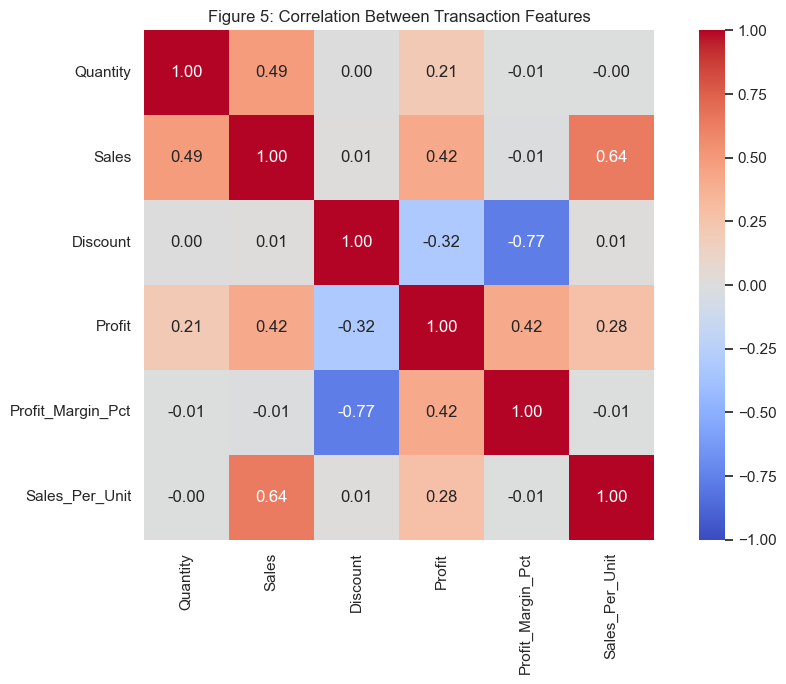


Figure saved: week4_correlation_heatmap.png

===== STRONGEST NEGATIVE CORRELATIONS =====
Discount           Profit_Margin_Pct   -0.766
                   Profit              -0.317
Sales              Profit_Margin_Pct   -0.010
Profit_Margin_Pct  Sales_Per_Unit      -0.007
Quantity           Profit_Margin_Pct   -0.006

===== STRONGEST POSITIVE CORRELATIONS =====
Sales     Sales_Per_Unit       0.639
Quantity  Sales                0.491
Sales     Profit               0.417
Profit    Profit_Margin_Pct    0.416
          Sales_Per_Unit       0.279


In [10]:

# STEP 10: Correlation Analysis

correlation_columns = [
    "Quantity",
    "Sales",
    "Discount",
    "Profit",
    "Profit_Margin_Pct",
    "Sales_Per_Unit"
]

correlation_matrix = transaction_features[
    correlation_columns
].corr(numeric_only=True)

print("===== CORRELATION MATRIX =====")
print(correlation_matrix.round(3).to_string())


# Visualize correlations
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)

plt.title("Figure 5: Correlation Between Transaction Features")
plt.tight_layout()

plt.savefig(
    "week4_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nFigure saved: week4_correlation_heatmap.png")


# Identify strongest positive and negative relationships
pairs = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
).stack().sort_values()

print("\n===== STRONGEST NEGATIVE CORRELATIONS =====")
print(pairs.head(5).round(3).to_string())

print("\n===== STRONGEST POSITIVE CORRELATIONS =====")
print(pairs.tail(5).sort_values(ascending=False).round(3).to_string())


In [11]:

# STEP 11: Customer Retention and Business Risk Analysis

# 1. Overall customer retention indicators
total_customers = customer_features["Customer ID"].nunique()

inactive_customers = (
    customer_features["Recency_Group"] == "Inactive"
).sum()

one_time_customers = (
    customer_features["Frequency_Group"] == "One-time"
).sum()

frequent_customers = (
    customer_features["Frequency_Group"] == "Frequent"
).sum()

print("===== CUSTOMER RETENTION INDICATORS =====")
print("Total customers:", total_customers)

print(
    "Inactive customers:",
    inactive_customers,
    f"({inactive_customers / total_customers * 100:.2f}%)"
)

print(
    "One-time customers:",
    one_time_customers,
    f"({one_time_customers / total_customers * 100:.2f}%)"
)

print(
    "Frequent customers:",
    frequent_customers,
    f"({frequent_customers / total_customers * 100:.2f}%)"
)


# 2. Profitability risk by category
category_risk = (
    transaction_features.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean"),
        Transactions=("Order ID", "size")
    )
    .reset_index()
)

category_risk["Profit_Margin_Pct"] = (
    category_risk["Profit"] / category_risk["Sales"] * 100
)

category_risk = category_risk.sort_values(
    "Profit_Margin_Pct"
)

print("\n===== CATEGORY PROFITABILITY RISK =====")
print(category_risk.round(2).to_string(index=False))


# 3. Save analysis outputs
category_risk.to_csv("week4_category_risk_analysis.csv", index=False)

print("\nSaved: week4_category_risk_analysis.csv")


===== CUSTOMER RETENTION INDICATORS =====
Total customers: 17415
Inactive customers: 9768 (56.09%)
One-time customers: 11979 (68.79%)
Frequent customers: 1969 (11.31%)

===== CATEGORY PROFITABILITY RISK =====
            Category   Sales    Profit  Average_Discount  Transactions  Profit_Margin_Pct
home and accessories 1245643 -57187.64              0.14          9516              -4.59
           hair care 1022151   3677.23              0.14          8203               0.36
           body care 2682942 590907.78              0.15         21062              22.02
             make up 1121222 368998.18              0.13          9017              32.91
           face care  445716 159018.10              0.11          3492              35.68

Saved: week4_category_risk_analysis.csv


===== MARKET PROFITABILITY RISK =====
      Market   Sales    Profit  Average_Discount  Transactions  Unique_Orders  Unique_Customers  Profit_Margin_Pct
Asia Pacific 1831648 228742.59              0.18         14302           7080              4941              12.49
      Africa  486811  66213.45              0.16          4587           2288              2055              13.60
       LATAM 1339726 216042.79              0.14         10294           5144              3702              16.13
        USCA 1372045 222770.12              0.15         10378           5203              2682              16.24
      Europe 1487444 331644.70              0.09         11729           6013              4035              22.30


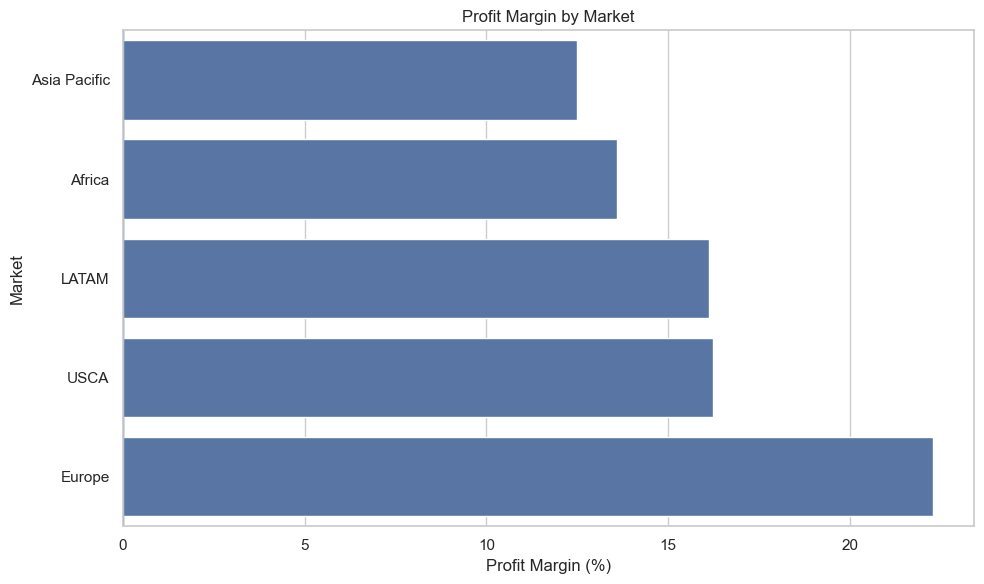


Saved:
1. week4_market_profitability_risk.png
2. week4_market_risk_analysis.csv


In [12]:

# STEP 12: Market-wise Profitability and Discount Analysis

market_risk = (
    transaction_features.groupby("Market")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Average_Discount=("Discount", "mean"),
        Transactions=("Order ID", "size"),
        Unique_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
)

market_risk["Profit_Margin_Pct"] = (
    market_risk["Profit"] / market_risk["Sales"] * 100
)

market_risk = market_risk.sort_values(
    "Profit_Margin_Pct"
)

print("===== MARKET PROFITABILITY RISK =====")
print(market_risk.round(2).to_string(index=False))


# Visual comparison of market profit margins
plt.figure(figsize=(10, 6))

sns.barplot(
    data=market_risk,
    x="Profit_Margin_Pct",
    y="Market"
)

plt.axvline(0, linewidth=1)
plt.title("Profit Margin by Market")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Market")
plt.tight_layout()

plt.savefig(
    "week4_market_profitability_risk.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

market_risk.to_csv("week4_market_risk_analysis.csv", index=False)

print("\nSaved:")
print("1. week4_market_profitability_risk.png")
print("2. week4_market_risk_analysis.csv")


In [13]:

# STEP 13: Final Business Insights Summary

insights = pd.DataFrame([
    {
        "Area": "Customer Retention",
        "Finding": "56.09% customers are inactive",
        "Business_Implication": "Investigate reactivation opportunities",
        "Recommended_Action": "Test targeted win-back campaigns"
    },
    {
        "Area": "Repeat Purchasing",
        "Finding": "68.79% customers are one-time buyers",
        "Business_Implication": "Repeat purchase potential needs investigation",
        "Recommended_Action": "Test post-purchase offers and reminders"
    },
    {
        "Area": "Customer Loyalty",
        "Finding": "11.31% customers are frequent buyers",
        "Business_Implication": "Frequent buyers may be suitable for loyalty initiatives",
        "Recommended_Action": "Evaluate a loyalty or rewards programme"
    },
    {
        "Area": "Category Profitability",
        "Finding": "Home and Accessories margin is -4.59%",
        "Business_Implication": "Category is generating an overall accounting loss in this dataset",
        "Recommended_Action": "Audit product costs, discounts, returns and pricing"
    },
    {
        "Area": "Category Profitability",
        "Finding": "Hair Care margin is 0.36%",
        "Business_Implication": "Profitability is close to break-even",
        "Recommended_Action": "Review product-level margins and promotional pricing"
    },
    {
        "Area": "Market Performance",
        "Finding": "Europe margin is 22.30%",
        "Business_Implication": "Europe has the strongest observed market margin",
        "Recommended_Action": "Investigate which products and customer groups contribute most"
    },
    {
        "Area": "Market Performance",
        "Finding": "Asia Pacific margin is 12.49%",
        "Business_Implication": "Margin is lower than other listed markets",
        "Recommended_Action": "Review discounting, costs and product mix"
    },
    {
        "Area": "Statistical Analysis",
        "Finding": "All six customer metrics tested had p-values below 0.05",
        "Business_Implication": "Active and inactive groups differ statistically on these metrics",
        "Recommended_Action": "Use effect sizes and business context before deciding interventions"
    }
])

print("===== FINAL BUSINESS INSIGHTS =====")
print(insights.to_string(index=False))

insights.to_csv("week4_business_insights.csv", index=False)

print("\nSaved: week4_business_insights.csv")


===== FINAL BUSINESS INSIGHTS =====
                  Area                                                 Finding                                              Business_Implication                                                  Recommended_Action
    Customer Retention                           56.09% customers are inactive                            Investigate reactivation opportunities                                    Test targeted win-back campaigns
     Repeat Purchasing                    68.79% customers are one-time buyers                     Repeat purchase potential needs investigation                             Test post-purchase offers and reminders
      Customer Loyalty                    11.31% customers are frequent buyers           Frequent buyers may be suitable for loyalty initiatives                             Evaluate a loyalty or rewards programme
Category Profitability                   Home and Accessories margin is -4.59% Category is generating an overall

In [14]:

# STEP 14: Final Analysis Summary for Report

print("===== DATASET SUMMARY =====")
print("Transaction records:", len(transaction_features))
print("Unique customers:", transaction_features["Customer ID"].nunique())
print("Unique orders:", transaction_features["Order ID"].nunique())
print(
    "Analysis period:",
    transaction_features["Order Date"].min().date(),
    "to",
    transaction_features["Order Date"].max().date()
)

print("\n===== YEARLY PERFORMANCE =====")
print(yearly_trend.round(2).to_string(index=False))

print("\n===== CATEGORY PERFORMANCE =====")
print(category_risk.round(2).to_string(index=False))

print("\n===== MARKET PERFORMANCE =====")
print(market_risk.round(2).to_string(index=False))

print("\n===== CUSTOMER STATISTICAL TESTS =====")
print(test_results.round(6).to_string(index=False))

print("\n===== FEATURE DATASET SHAPES =====")
print("Customer features:", customer_features.shape)
print("Transaction features:", transaction_features.shape)

print("\n===== GENERATED FIGURES =====")
figure_files = [
    "week4_numerical_distributions.png",
    "week4_numerical_boxplots.png",
    "week4_monthly_trends.png",
    "week4_yearly_comparison.png",
    "week4_category_performance.png",
    "week4_market_performance.png",
    "week4_customer_activity_analysis.png",
    "week4_correlation_heatmap.png",
    "week4_market_profitability_risk.png"
]

import os

for filename in figure_files:
    print(filename, "Exists:", os.path.exists(filename))



===== DATASET SUMMARY =====
Transaction records: 51290
Unique customers: 17415
Unique orders: 25728
Analysis period: 2020-01-01 to 2023-12-31

===== YEARLY PERFORMANCE =====
 Year  Total_Sales  Total_Profit  Unique_Orders  Sales_Growth_Pct  Profit_Growth_Pct  Orders_Growth_Pct
 2020      1148361     207116.12           4515               NaN                NaN                NaN
 2021      1405876     259696.96           5473             22.42              25.39              21.22
 2022      1770790     318671.89           6883             25.96              22.71              25.76
 2023      2192647     279928.68           8857             23.82             -12.16              28.68

===== CATEGORY PERFORMANCE =====
            Category   Sales    Profit  Average_Discount  Transactions  Profit_Margin_Pct
home and accessories 1245643 -57187.64              0.14          9516              -4.59
           hair care 1022151   3677.23              0.14          8203               0.36
  